# EEG performance metrics: reading against copy typing

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats

DATA = Path(".")                                          # folder with the exports
EXPORT = "filtered"                                       # main analysis; "unfiltered" for the sensitivity check
FILES = {"filtered":   ["full_read_filtered.csv", "full_type_filtered.csv"],
         "unfiltered": ["full_read_no_filter.csv", "full_type_no_filter.csv"]}
SHARED = ["full_read_post_ques.csv", "full_type_post_ques.csv", "full_type_motor_and_read.csv"]   # used in both runs; the
                                                          # filter setting applies to the reading and typing sessions only
OUT = Path(f"results_{EXPORT}")                           # tables and LaTeX of this run
FIGS = Path("figures")                                    # charts of both runs, next to the notebook; every file
                                                          # name ends in _filtered or _unfiltered
OUT.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
PHASES = {"Reading": "Reading", "Reading_post_question": "Reading post-question",      # marker label -> name, in order
          "Motor baseline": "Motor baseline", "Reading baseline": "Reading baseline",
          "Typing": "Typing", "Typing_post_question": "Typing post-question"}
PAIRS = {"Reading vs typing": ("Reading", "Typing"),                                    # paired t-tests
         "Post-question: reading vs typing": ("Reading post-question", "Typing post-question"),
         "Reading vs reading baseline": ("Reading", "Reading baseline"),   # check: reading in both sessions
         "Motor baseline vs reading baseline": ("Reading baseline", "Motor baseline")}   # both in the typing session
METRICS = ["Attention", "Engagement", "Excitement", "Focus", "Interest", "Relaxation", "Stress", "Cognitivestress"]
LABELS = {m: m for m in METRICS} | {"Cognitivestress": "Cognitive stress"}   # names shown in charts and tables
TITLE = "EEG Performance metrics"                         # start of every chart title
FIGURES = {}                                              # chart file -> (caption, LaTeX note), filled by the chart cells
SUBJECT_TO_PID = {
    874464: "P01", 875879: "P02", 876011: "P03", 877166: "P05", 877397: "P06", 877694: "P07",
    877925: "P08", 885416: "P09", 885450: "P10", 893435: "P11", 893484: "P12", 895856: "P13",
    899315: "P14", 899358: "P15", 904556: "P16", 904952: "P17", 911388: "P18", 912740: "P19",
    913037: "P20", 914753: "P21", 915644: "P22", 915842: "P23", 917901: "P24", 921653: "P27",
}
no_nf_read_first = ["P01", "P07", "P12", "P18", "P22", "P23"]
no_nf_type_first = ["P06", "P10", "P11", "P16", "P20", "P27"]
nf_read_first    = ["P08", "P09", "P14", "P13", "P17", "P24"]
nf_type_first    = ["P02", "P03", "P05", "P15", "P19", "P21"]

# load the exports; the marker label gives the phase; a recording found in two files is kept once
d = pd.concat([pd.read_csv(DATA / f) for f in FILES[EXPORT] + SHARED], ignore_index=True)
d = d.drop_duplicates(["record_id", "Timestamp", "Detection Name"])
d["phase"], d["pid"] = d["Marker Label"].map(PHASES), d["subject_id"].map(SUBJECT_TO_PID)

# headset disconnection: if attention stays empty for 60 s or more until the end of a phase, drop that end
key = d["record_id"] + " " + d["phase"]
d["t"] = d["Timestamp"] - d.groupby(key)["Timestamp"].transform("min")
last = d[(d["Detection Name"] == "Attention") & d["Detection Value"].notna()].groupby(key)["t"].max()
cut_at = last.where(d.groupby(key)["t"].max() - last >= 60)
d = d[~(d["t"] > key.map(cut_at))]

# each person's average per phase, then the mean and SD across people
means = d.groupby(["phase", "pid", "Detection Name"])["Detection Value"].mean().unstack()[METRICS].reset_index()
summary = (means.groupby("phase")[METRICS].agg(["mean", "std"]).rename(columns={"std": "SD"})
           .rename_axis(columns=[None, None]).reindex(PHASES.values()))
summary.insert(0, ("n", ""), means.groupby("phase").size())

# paired t-tests per metric (people with both phases), the difference in %, and p-adj (Holm) over the 8 metrics
wide = means.pivot(index="pid", columns="phase", values=METRICS)
tests = {}
for name, (a, b) in PAIRS.items():
    p, pct = {}, {}
    for m in METRICS:
        x = wide[[(m, a), (m, b)]].dropna()
        p[m] = stats.ttest_rel(x[(m, b)], x[(m, a)]).pvalue
        pct[m] = 100 * (x[(m, b)].mean() / x[(m, a)].mean() - 1)        # second phase relative to the first
    p = pd.Series(p)
    tests[(name, "Δ%")] = pd.Series(pct).round(1)
    tests[(name, "p")] = p
    tests[(name, "p-adj (Holm)")] = (p.sort_values() * np.arange(len(p), 0, -1)).cummax().clip(upper=1)
tests = pd.DataFrame(tests).reindex(METRICS).rename_axis("metric")
tests = tests.sort_values([("Reading vs typing", "p-adj (Holm)"), ("Reading vs typing", "p")])   # significant first

# NF check: NF against No-NF, for reading and for typing (different people, so a Welch t-test)
means["nf"] = means["pid"].map({p: "NF" for p in nf_read_first + nf_type_first}
                               | {p: "No-NF" for p in no_nf_read_first + no_nf_type_first})
nf_check = {}
for ph in ["Reading", "Typing"]:
    for m in METRICS:
        x = means[means["phase"] == ph]
        a, b = x.loc[x["nf"] == "NF", m].dropna(), x.loc[x["nf"] == "No-NF", m].dropna()
        nf_check[(ph, m)] = {"n NF": len(a), "NF": a.mean(), "NF SD": a.std(),
                             "n No-NF": len(b), "No-NF": b.mean(), "No-NF SD": b.std(),
                             "Δ%": round(100 * (a.mean() / b.mean() - 1), 1),   # NF relative to No-NF
                             "p": stats.ttest_ind(a, b, equal_var=False).pvalue}
nf_check = pd.DataFrame(nf_check).T.astype({"n NF": int, "n No-NF": int}).rename_axis(["phase", "metric"])

summary.round(4).to_csv(OUT / "pm_group_summary.csv")
tests.round(4).to_csv(OUT / "pm_paired_tests.csv")
nf_check.round(4).to_csv(OUT / "pm_nf_check.csv")
print(f"{EXPORT} exports; tables and LaTeX in {OUT}/, charts in {FIGS}/ (names ending in _{EXPORT})")
display(summary.round(3), tests.round(3))
nf_check.round(3)

filtered exports; tables and LaTeX in results_filtered/, charts in figures/ (names ending in _filtered)


n Attention        Engagement        Excitement  \
                               mean     SD       mean     SD       mean   
phase                                                                     
Reading                24     0.650  0.078      0.387  0.083      0.390   
Reading post-question  24     0.523  0.111      0.517  0.102      0.499   
Motor baseline         24     0.511  0.127      0.547  0.155      0.456   
Reading baseline       23     0.611  0.095      0.415  0.108      0.418   
Typing                 22     0.600  0.086      0.477  0.116      0.469   
Typing post-question   24     0.552  0.140      0.468  0.147      0.458   

                              Focus        Interest        Relaxation         \
                          SD   mean     SD     mean     SD       mean     SD   
phase                                                                          
Reading                0.065  0.291  0.086    0.377  0.040      0.187  0.060   
Reading post-question  0.083  0.296  0.070    0.428  0.057      0.234  0.126   
Motor baseline         0.118  0.245  0.087    0.383  0.047      0.218  0.102   
Reading baseline       0.107  0.332  0.119    0.407  0.063      0.209  0.089   
Typing                 0.105  0.299  0.085    0.423  0.038      0.205  0.082   
Typing post-question   0.140  0.304  0.159    0.435  0.100      0.256  0.148   

                      Stress        Cognitivestress         
                        mean     SD            mean     SD  
phase                                                       
Reading                0.595  0.063           0.429  0.087  
Reading post-question  0.618  0.047           0.512  0.085  
Motor baseline         0.596  0.070           0.573  0.132  
Reading baseline       0.591  0.077           0.443  0.085  
Typing                 0.568  0.043           0.498  0.104  
Typing post-question   0.617  0.077           0.451  0.122

Reading vs typing                      \
                               Δ%      p p-adj (Holm)   
metric                                                  
Interest                     12.0  0.001        0.008   
Engagement                   23.7  0.002        0.015   
Excitement                   20.5  0.002        0.015   
Cognitivestress              15.8  0.023        0.115   
Attention                    -8.1  0.043        0.172   
Stress                       -3.6  0.217        0.651   
Relaxation                   10.1  0.349        0.697   
Focus                         1.7  0.835        0.835   

                Post-question: reading vs typing                      \
                                              Δ%      p p-adj (Holm)   
metric                                                                 
Interest                                     1.6  0.784        1.000   
Engagement                                  -9.5  0.133        0.934   
Excitement                                  -8.3  0.170        1.000   
Cognitivestress                            -12.0  0.017        0.140   
Attention                                    5.6  0.294        1.000   
Stress                                      -0.1  0.948        1.000   
Relaxation                                   9.6  0.552        1.000   
Focus                                        2.5  0.822        1.000   

                Reading vs reading baseline                      \
                                         Δ%      p p-adj (Holm)   
metric                                                            
Interest                                7.9  0.080        0.636   
Engagement                              6.6  0.404        1.000   
Excitement                              7.9  0.254        1.000   
Cognitivestress                         2.7  0.643        1.000   
Attention                              -5.6  0.128        0.770   
Stress                                  0.1  0.942        1.000   
Relaxation                             10.4  0.306        1.000   
Focus                                  15.8  0.095        0.668   

                Motor baseline vs reading baseline                      
                                                Δ%      p p-adj (Holm)  
metric                                                                  
Interest                                      -5.4  0.206        0.823  
Engagement                                    31.4  0.004        0.026  
Excitement                                     9.1  0.306        0.918  
Cognitivestress                               28.7  0.001        0.009  
Attention                                    -16.8  0.004        0.026  
Stress                                         1.4  0.736        1.000  
Relaxation                                     4.7  0.705        1.000  
Focus                                        -25.9  0.019        0.096

n NF     NF  NF SD  n No-NF  No-NF  No-NF SD    Δ%  \
phase   metric                                                                
Reading Attention          12  0.668  0.069       12  0.632     0.085   5.7   
        Engagement         12  0.387  0.087       12  0.386     0.083   0.1   
        Excitement         12  0.374  0.071       12  0.406     0.058  -8.0   
        Focus              12  0.260  0.044       12  0.321     0.108 -19.2   
        Interest           12  0.396  0.030       12  0.358     0.040  10.6   
        Relaxation         12  0.187  0.070       12  0.186     0.052   0.4   
        Stress             12  0.582  0.064       12  0.607     0.061  -4.1   
        Cognitivestress    12  0.426  0.095       12  0.432     0.081  -1.5   
Typing  Attention          10  0.589  0.110       12  0.610     0.064  -3.4   
        Engagement         10  0.515  0.138       12  0.445     0.087  15.8   
        Excitement         10  0.490  0.133       12  0.451     0.076   8.6   
        Focus              10  0.305  0.071       12  0.293     0.098   4.1   
        Interest           10  0.433  0.041       12  0.415     0.035   4.4   
        Relaxation         10  0.197  0.085       12  0.211     0.083  -6.9   
        Stress             10  0.564  0.050       12  0.572     0.038  -1.5   
        Cognitivestress    10  0.529  0.131       12  0.473     0.070  11.8   

                             p  
phase   metric                  
Reading Attention        0.266  
        Engagement       0.987  
        Excitement       0.231  
        Focus            0.087  
        Interest         0.016  
        Relaxation       0.978  
        Stress           0.339  
        Cognitivestress  0.861  
Typing  Attention        0.602  
        Engagement       0.183  
        Excitement       0.427  
        Focus            0.744  
        Interest         0.288  
        Relaxation       0.689  
        Stress           0.662  
        Cognitivestress  0.248

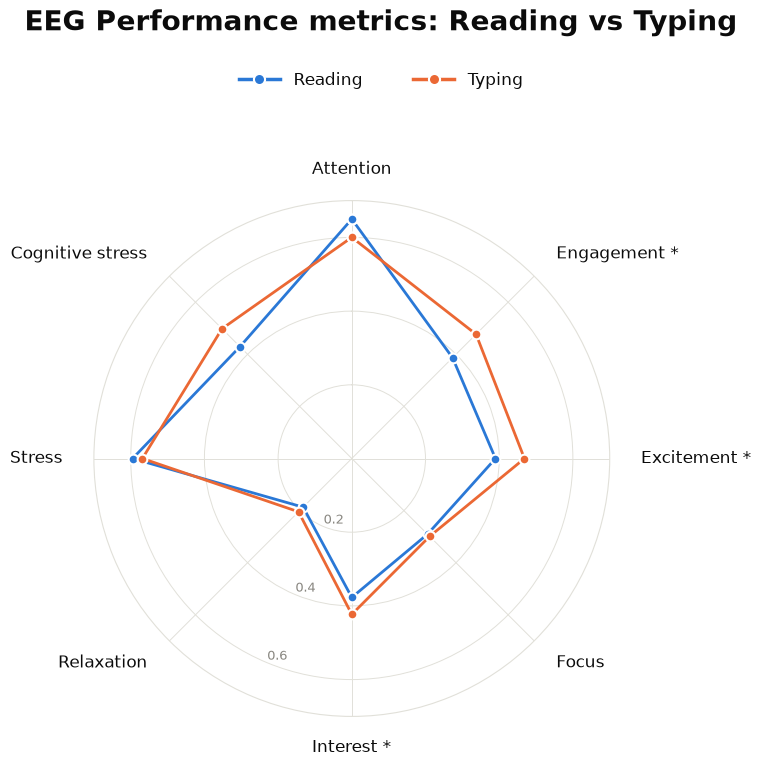

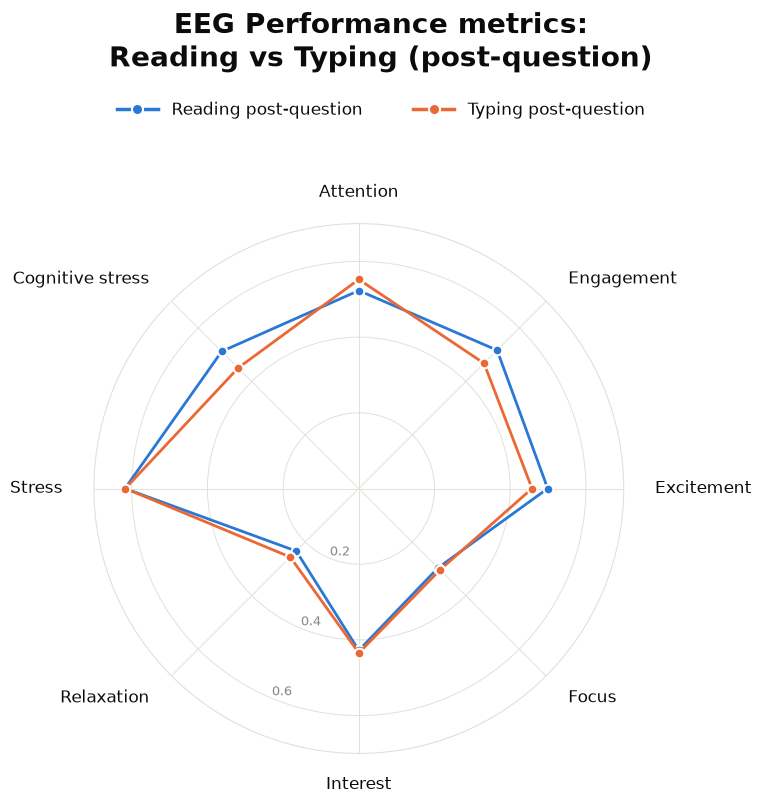

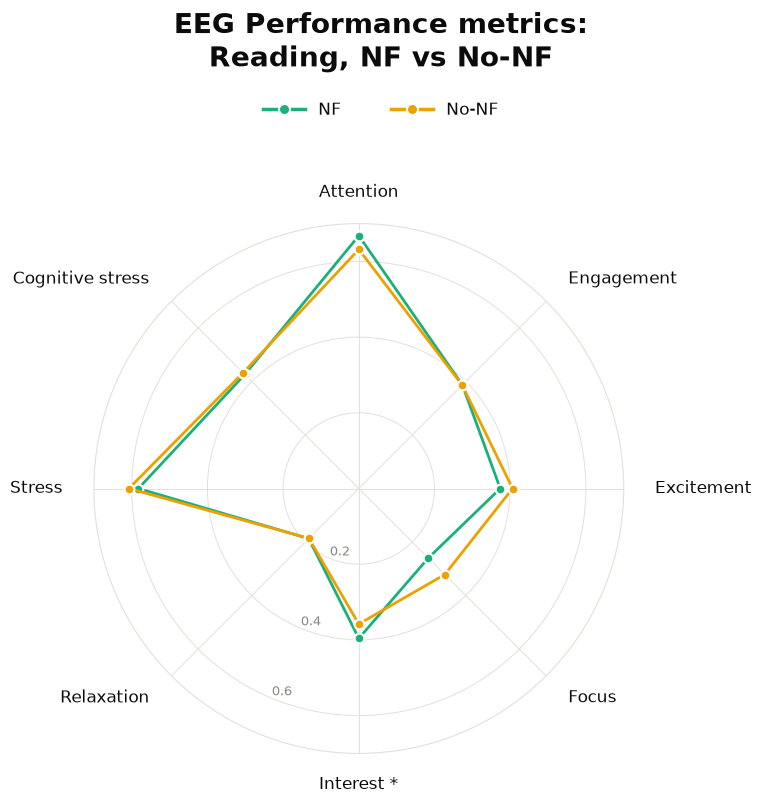

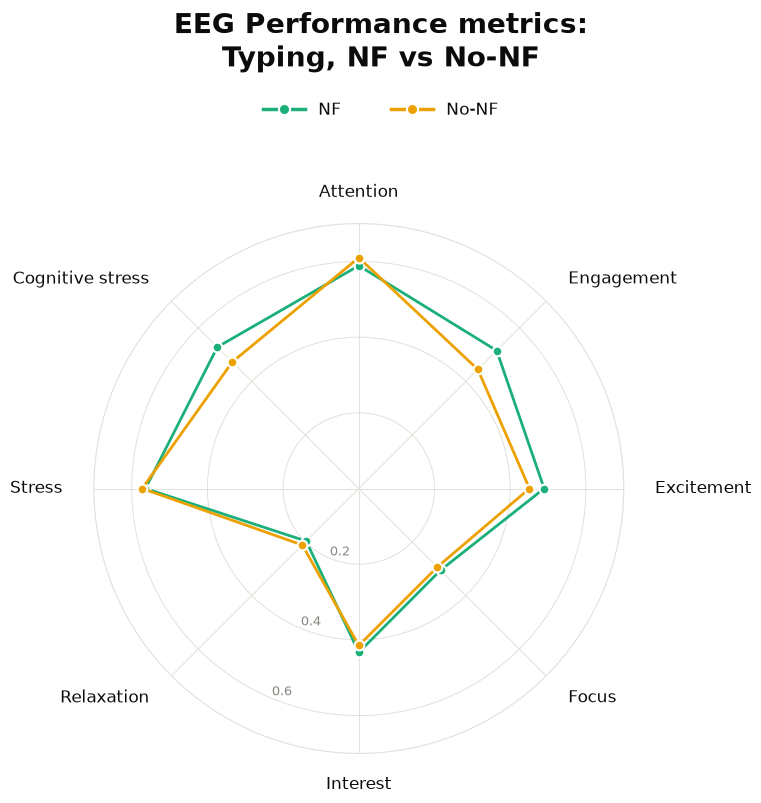

In [2]:
import re
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SURFACE, INK, INK_2, MUTED, GRID = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
READING, TYPING, NF, NO_NF = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
FILL = 0                                                   # shading inside each line; 0 keeps the chart area white
mean = summary.xs("mean", axis=1, level=1)[METRICS]
angles = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False)
closed = np.r_[angles, angles[:1]]

from PIL import Image

def save_png(fig, file):                                   # white background without a transparency layer
    fig.savefig(file, dpi=200, facecolor=SURFACE, bbox_inches="tight")
    Image.open(file).convert("RGB").save(file)

def spider(title, series, labels, file, rmax, subtitle=None):
    """One spider chart in its own figure. series: [(legend label, values per metric, colour)]."""
    two_lines = len(title) > 42                            # long titles break after the colon
    extra = 0.3 * two_lines + 0.3 * bool(subtitle)
    fig = plt.figure(figsize=(7.5, 8.0 + extra), facecolor=SURFACE, layout="constrained")
    head, body = fig.subfigures(2, 1, height_ratios=[1.0 + extra, 7.0], facecolor=SURFACE)
    head.suptitle(title.replace(": ", ":\n", 1) if two_lines else title, color=INK, fontsize=20, fontweight="bold")
    if subtitle:
        head.text(0.5, 0.42, subtitle, ha="center", va="center", color=INK_2, fontsize=13)
    head.legend(handles=[Line2D([], [], color=c, lw=2.5, marker="o", ms=8, mec=SURFACE, mew=1.5, label=label)
                         for label, _, c in series],
                loc="lower center", ncol=len(series), frameon=False, fontsize=12, labelcolor=INK,   # colour key
                handlelength=2.5, columnspacing=3)
    ax = body.add_subplot(projection="polar")
    ax.set_facecolor(SURFACE)
    ax.set_theta_offset(np.pi / 2)                     # first metric at the top, then clockwise
    ax.set_theta_direction(-1)
    for _, values, color in series:
        v = values.reindex(METRICS).to_numpy(dtype=float)
        ax.plot(closed, np.r_[v, v[:1]], color=color, lw=2, marker="o", ms=7, mec=SURFACE, mew=1.5)
        if FILL:
            ax.fill(closed, np.r_[v, v[:1]], color=color, alpha=FILL)
    ax.set_xticks(angles, labels, color=INK, fontsize=12)
    ax.tick_params(axis="x", pad=12)
    for label, a in zip(ax.get_xticklabels(), angles):           # labels on the sides grow away from the circle
        label.set_horizontalalignment("left" if np.sin(a) > 0.1 else "right" if np.sin(a) < -0.1 else "center")
    ax.set_ylim(0, rmax)
    ax.set_yticks(np.arange(0.2, rmax + 1e-9, 0.2))
    ax.set_rlabel_position(180 + 180 / len(METRICS))     # radial labels between Interest and Relaxation
    ax.tick_params(axis="y", labelsize=9, labelcolor=MUTED)
    ax.grid(color=GRID, lw=0.7)
    ax.spines["polar"].set_color(GRID)
    save_png(fig, file)
    plt.show()

def both(a, b):                                           # people with every metric in both phases
    return int((wide.xs(a, axis=1, level=1).notna().all(axis=1) & wide.xs(b, axis=1, level=1).notna().all(axis=1)).sum())

# the group charts: (file name, title, series, star per metric, LaTeX note); the notes go under the figures in LaTeX (cell 5)
CHARTS = []
for name, title in [("Reading vs typing", f"{TITLE}: Reading vs Typing"),
                    ("Post-question: reading vs typing", f"{TITLE}: Reading vs Typing (post-question)")]:
    a, b = PAIRS[name]
    CHARTS.append(("pm_spider_" + re.sub(r"[^a-z]+", "_", name.lower()).strip("_"), title,
                   [(ph, mean.loc[ph], c) for ph, c in zip((a, b), [READING, TYPING])],
                   tests[(name, "p-adj (Holm)")] < 0.05,
                   rf"Mean across participants on Emotiv's 0--1 scale ($n = {both(a, b)}$ with both phases). "
                   r"* $p_{\mathrm{Holm}} < 0.05$, paired $t$-test, Holm-adjusted over the eight metrics."))
for ph in ["Reading", "Typing"]:                                                    # NF against No-NF
    x = nf_check.loc[ph]
    CHARTS.append((f"pm_spider_{ph.lower()}_with_vs_without_nf", f"{TITLE}: {ph}, NF vs No-NF",
                   [("NF", x["NF"], NF), ("No-NF", x["No-NF"], NO_NF)],
                   x["p"].astype(float) < 0.05,
                   rf"Mean across participants on Emotiv's 0--1 scale (NF $n = {x['n NF'].iloc[0]}$, "
                   rf"No-NF $n = {x['n No-NF'].iloc[0]}$). * $p < 0.05$, Welch $t$-test, unadjusted."))
rmax = np.ceil(10 * max(v.astype(float).max() for _, _, series, _, _ in CHARTS for _, v, _ in series)) / 10   # same scale

for stem, title, series, stars, note in CHARTS:
    file = FIGS / f"{stem}_{EXPORT}.png"
    spider(title, series, [LABELS[m] + (" *" if stars[m] else "") for m in METRICS], file, rmax)
    FIGURES[str(file)] = (title, note)

No chart for P19, P24: no reading or no typing in these exports.


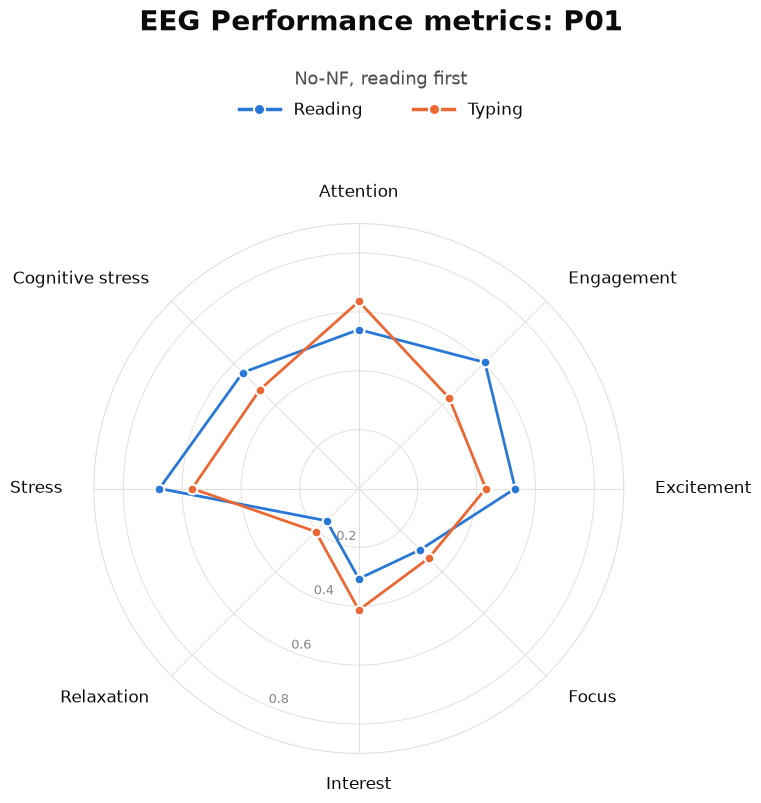

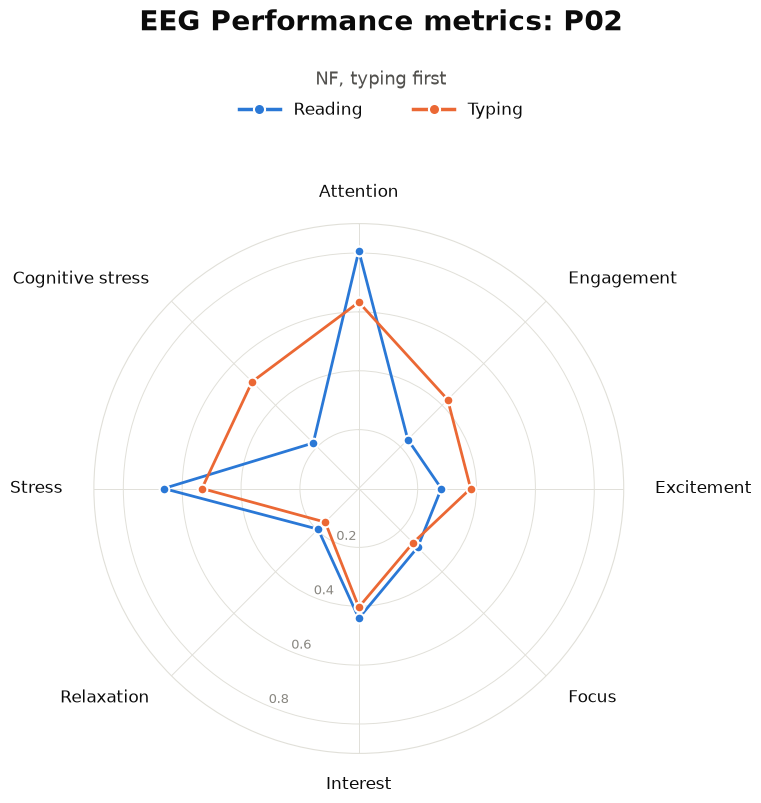

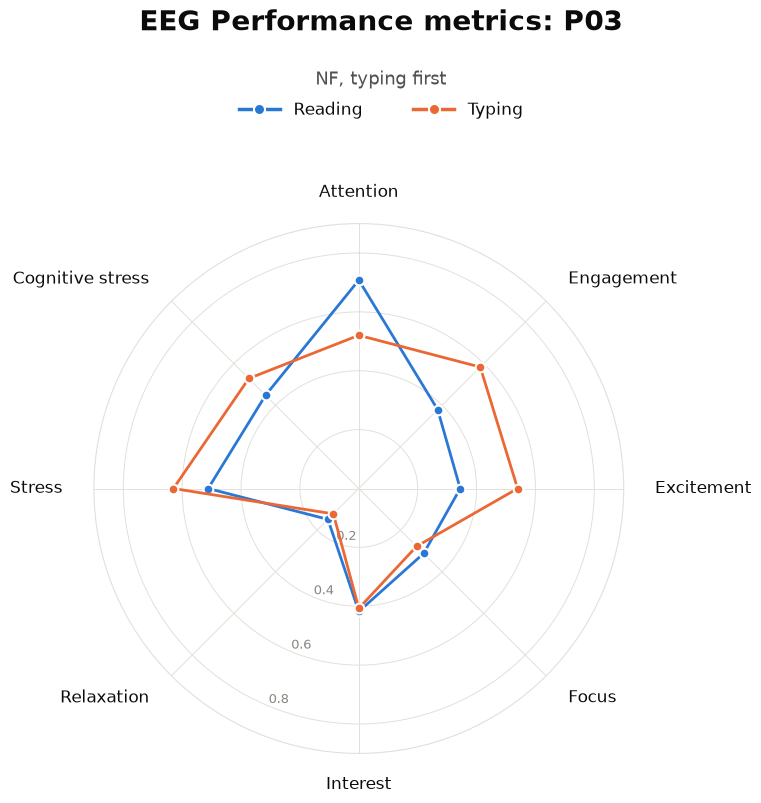

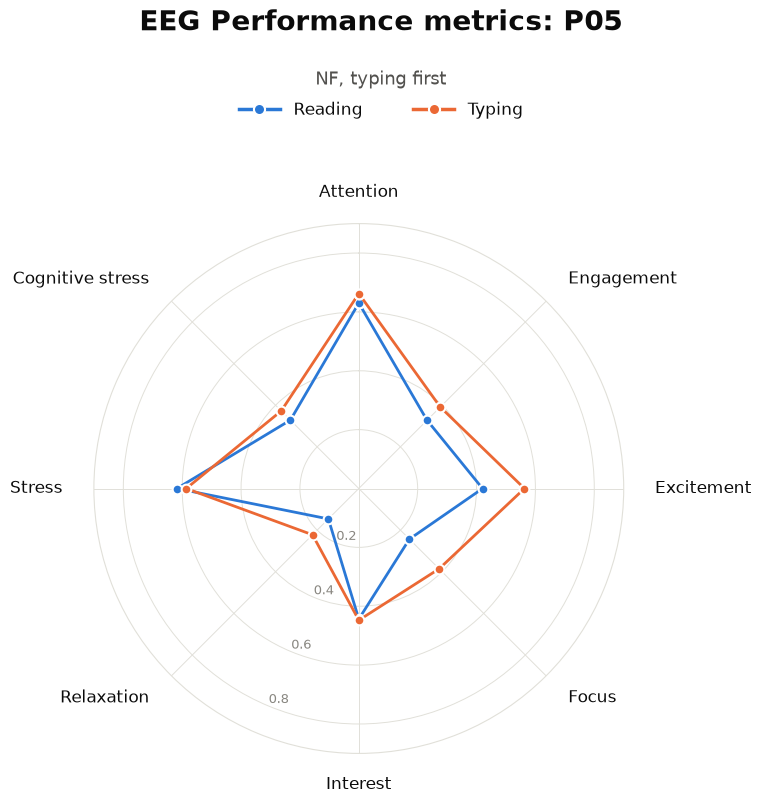

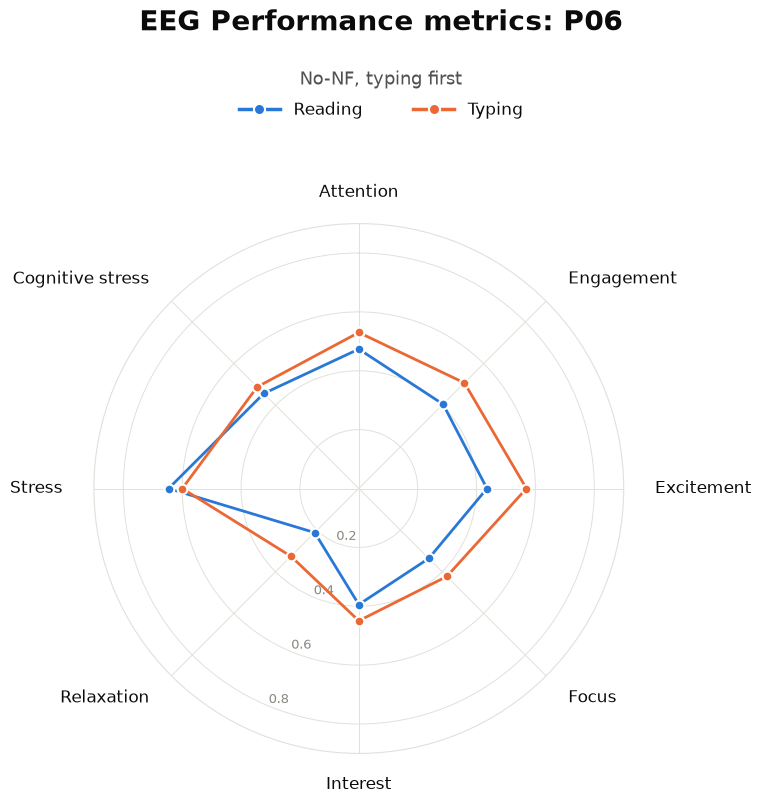

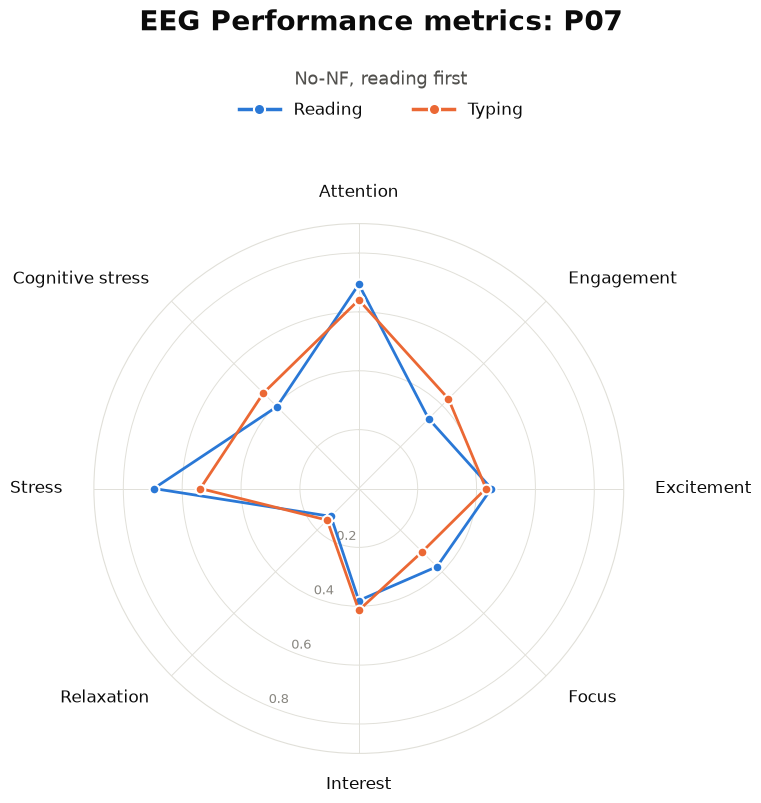

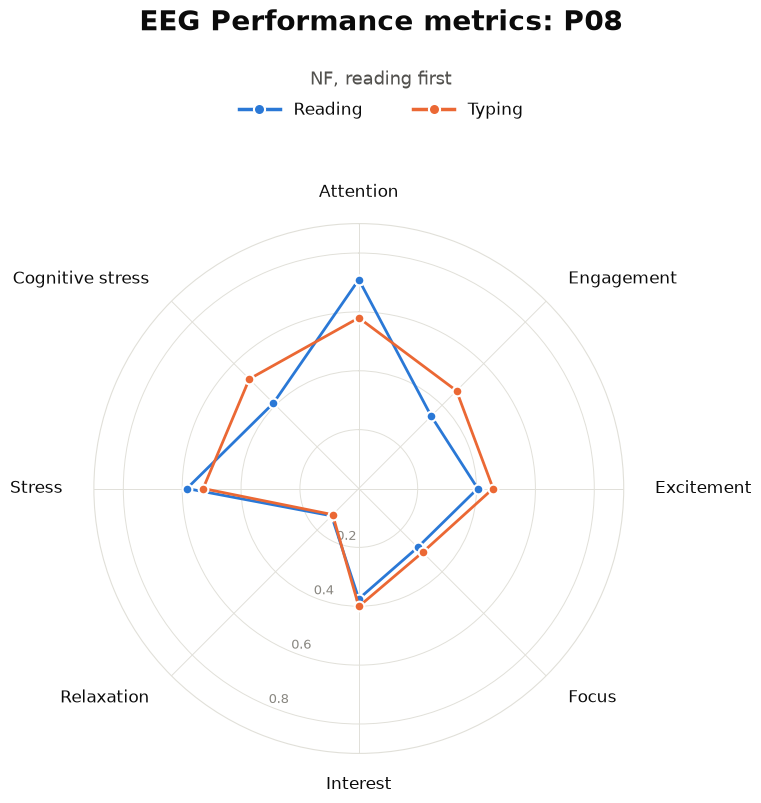

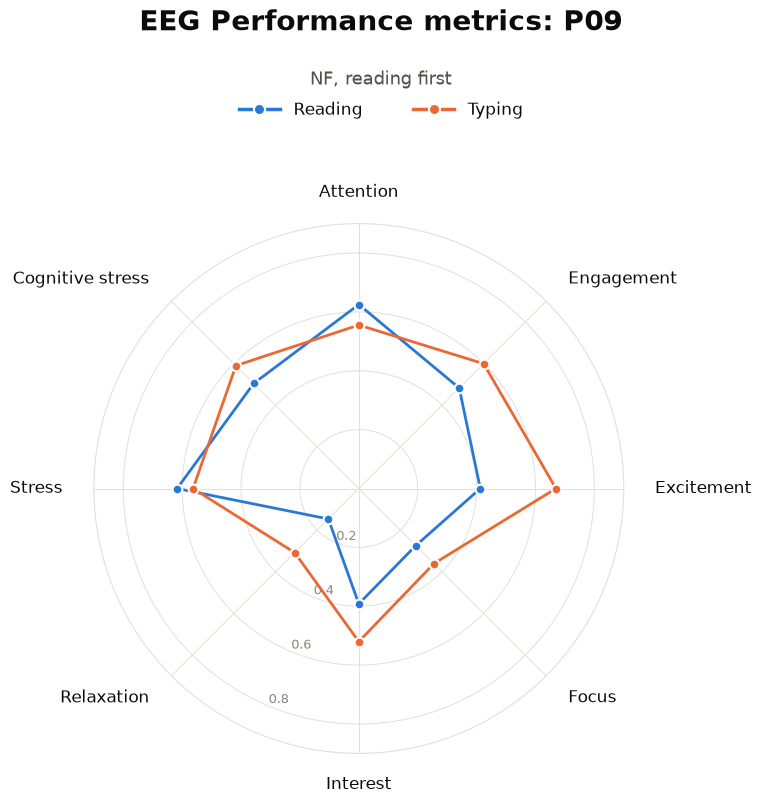

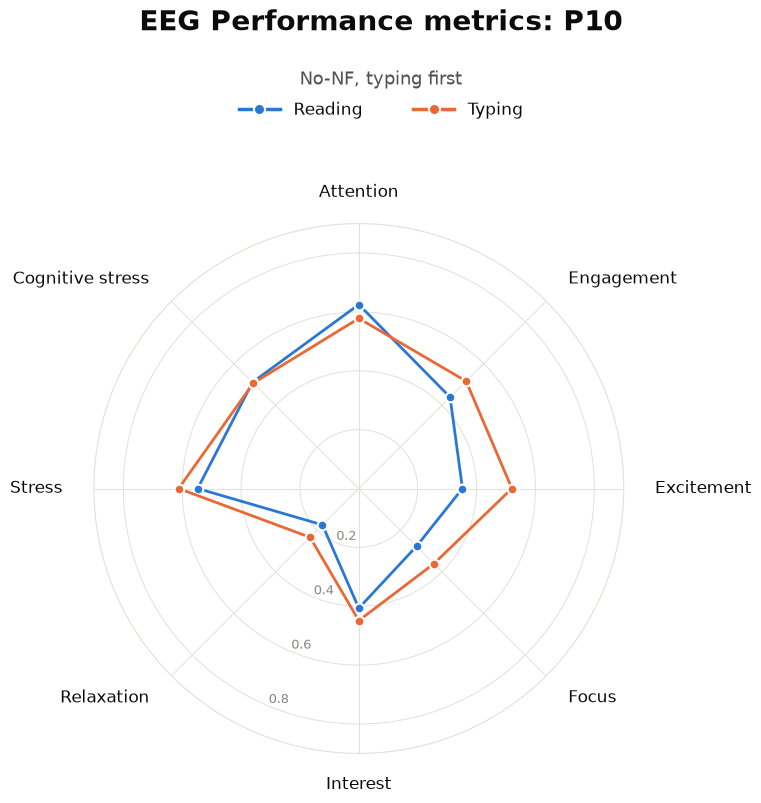

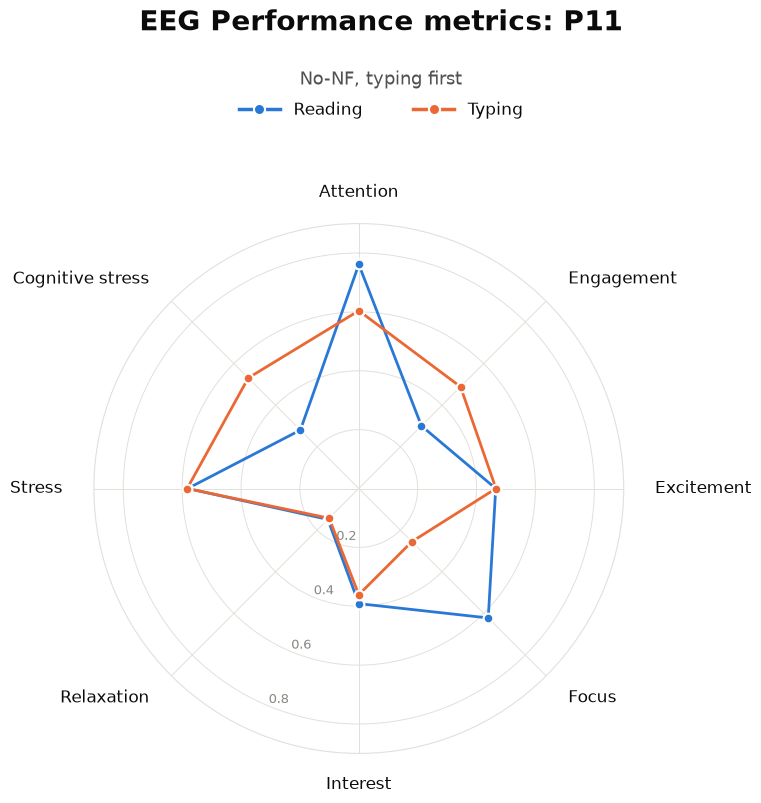

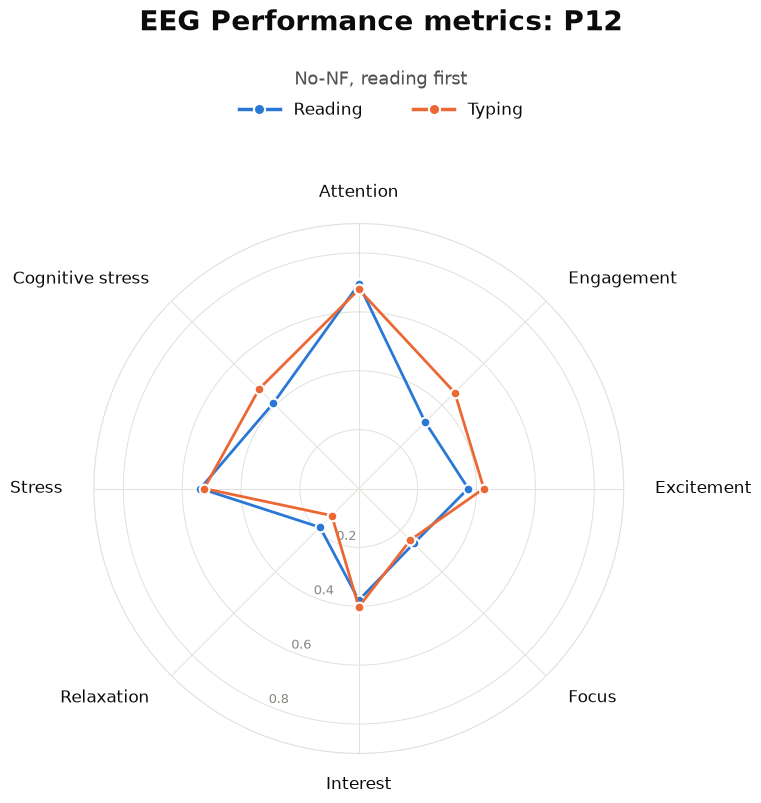

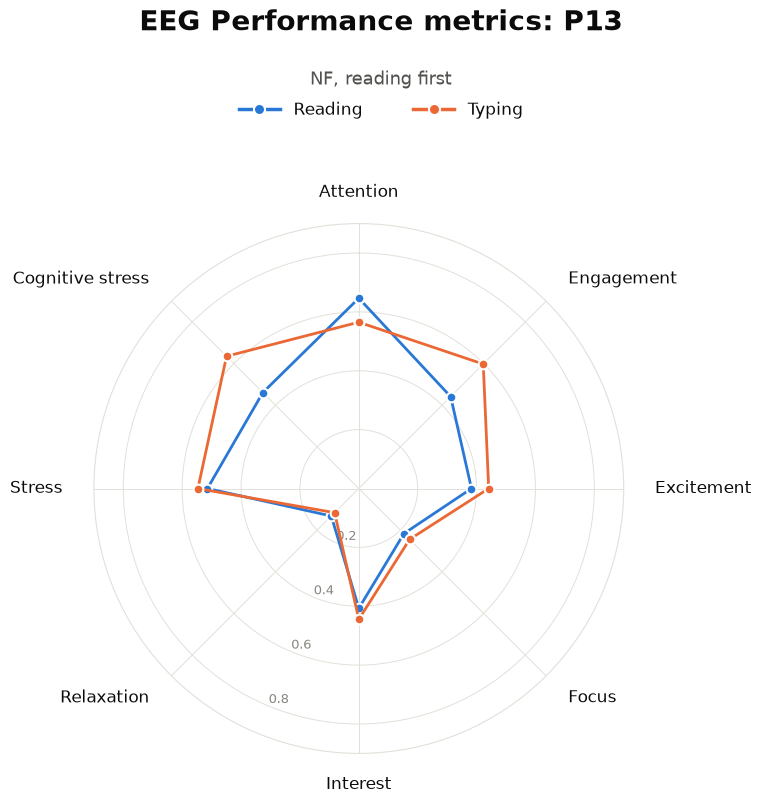

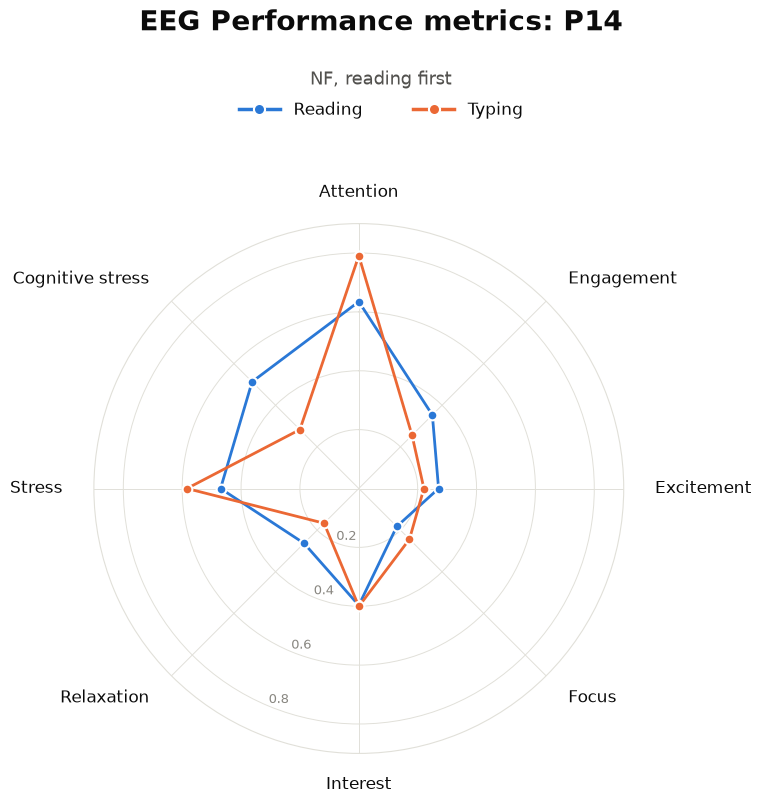

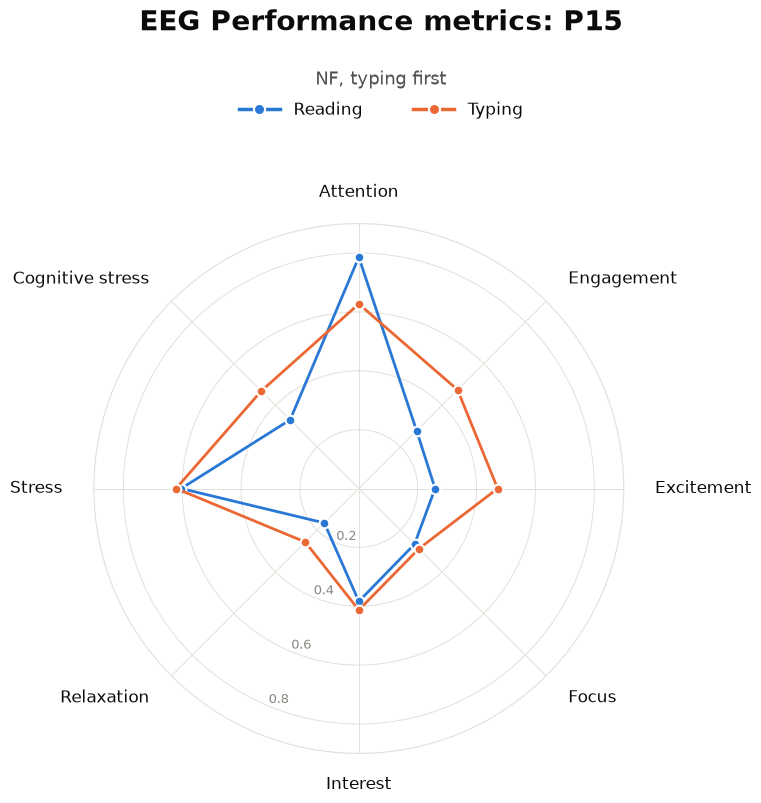

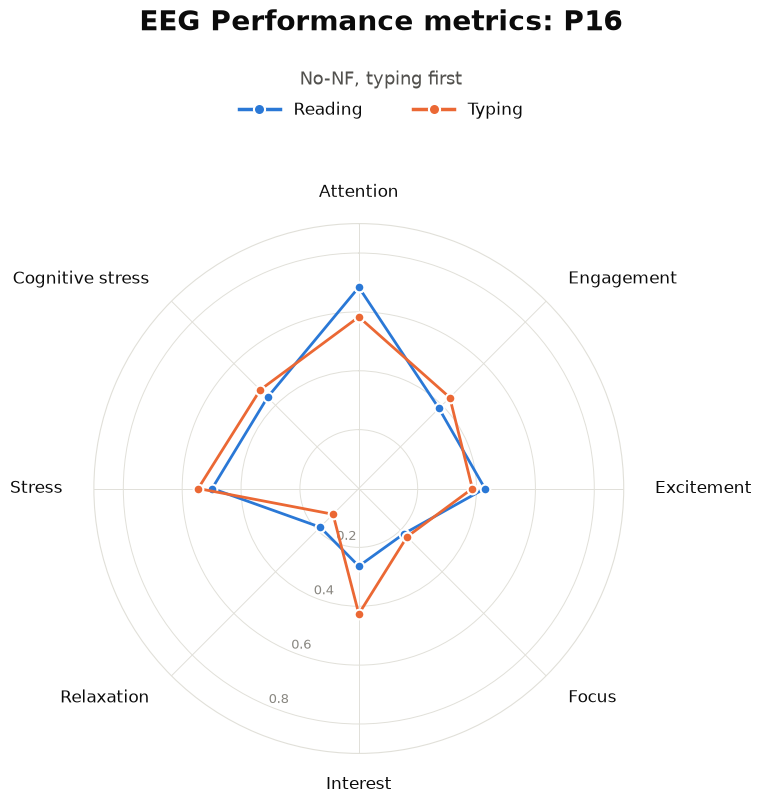

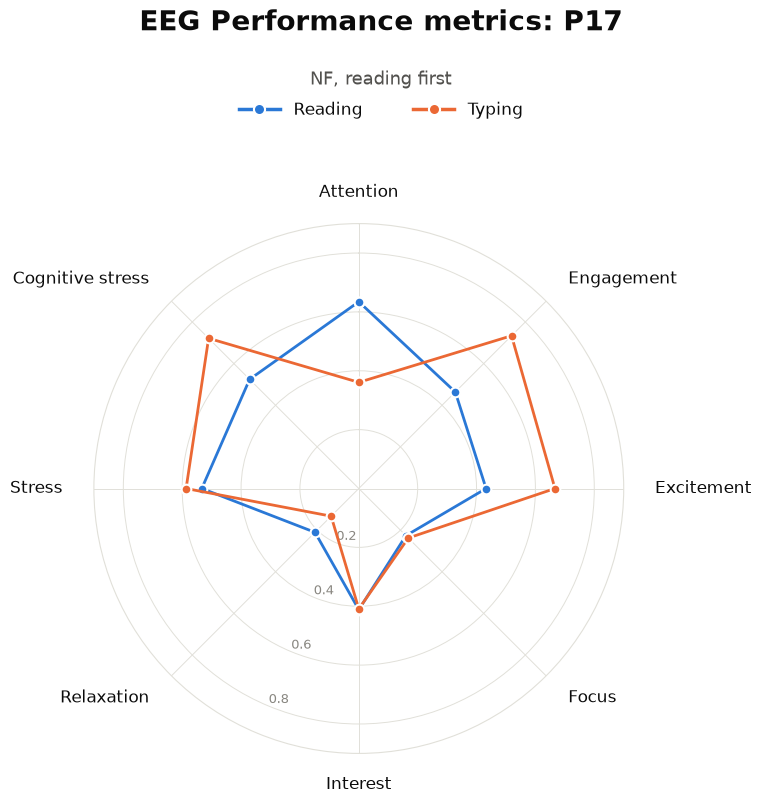

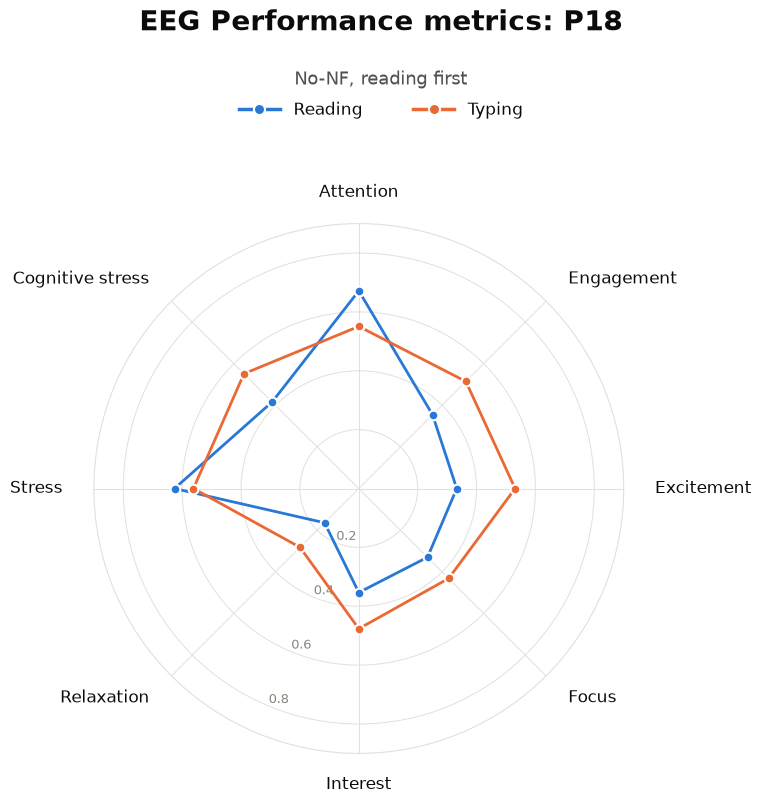

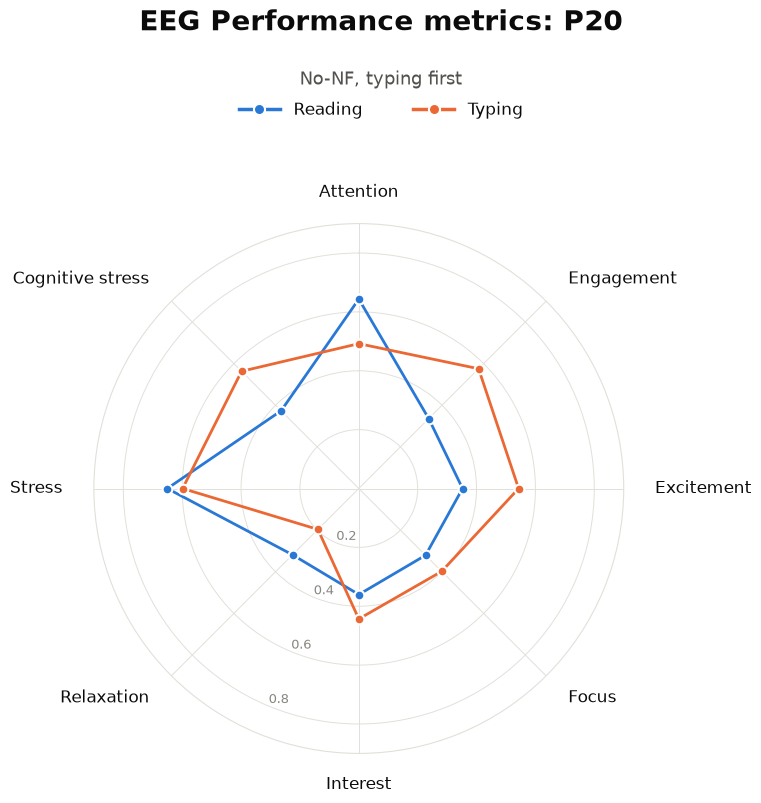

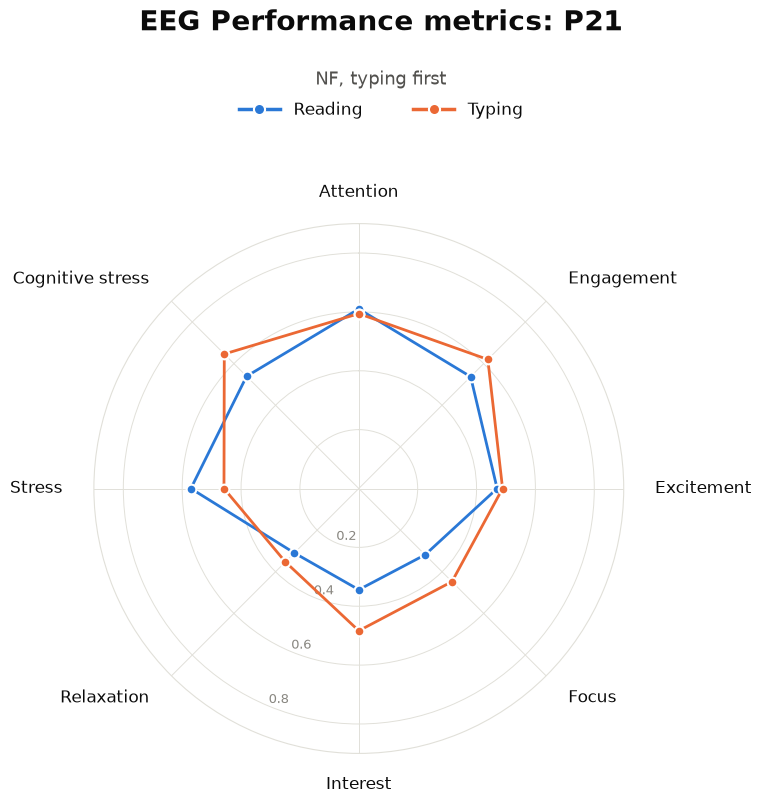

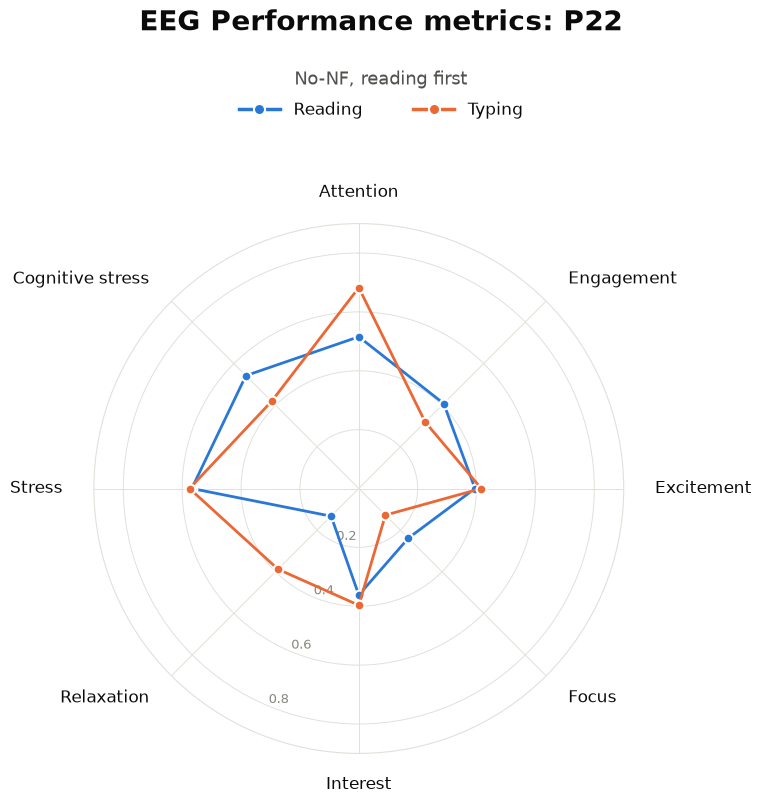

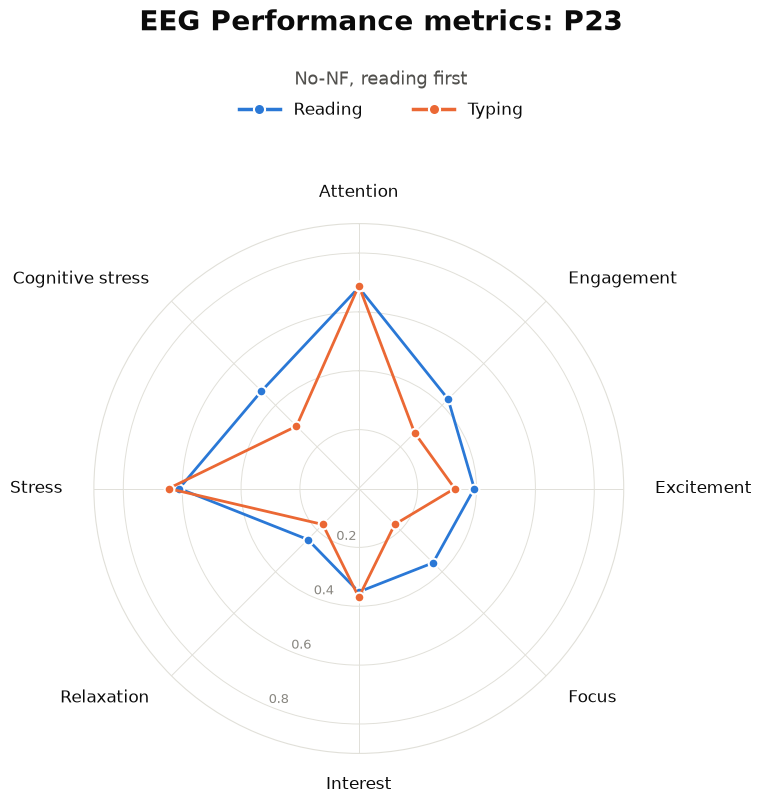

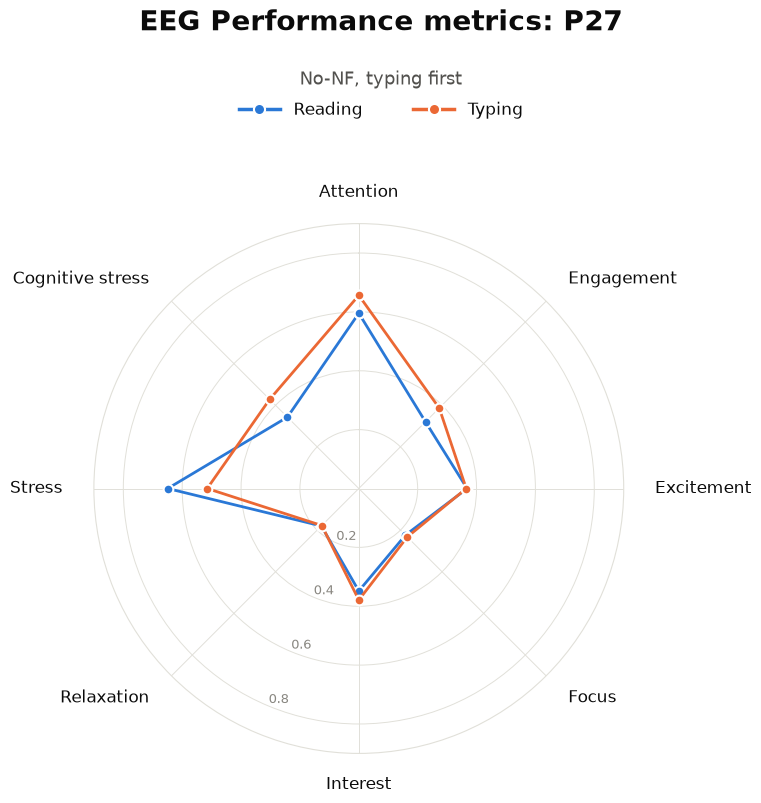

In [3]:
# one spider chart per participant: their own average in each phase (uses spider() from the cell above)
INDIVIDUAL = "Reading vs typing"                          # the pair from PAIRS to draw for each person
a, b = PAIRS[INDIVIDUAL]
group = {p: g for g, people in {"No-NF, reading first": no_nf_read_first, "No-NF, typing first": no_nf_type_first,
                                "NF, reading first": nf_read_first, "NF, typing first": nf_type_first}.items()
         for p in people}
person = {ph: wide.xs(ph, axis=1, level=1)[METRICS] for ph in (a, b)}           # person x metric, per phase
people = [p for p in wide.index if person[a].loc[p].notna().all() and person[b].loc[p].notna().all()]
missing = sorted(set(wide.index) - set(people))
if missing:
    print(f"No chart for {', '.join(missing)}: no {a.lower()} or no {b.lower()} in these exports.")
rmax_people = np.ceil(10 * max(person[ph].loc[people].max().max() for ph in (a, b))) / 10   # same scale for everyone
folder = FIGS / "spider_individual"
folder.mkdir(exist_ok=True)
for p in people:
    file = folder / f"pm_spider_{p}_{EXPORT}.png"
    spider(f"{TITLE}: {p}", [(a, person[a].loc[p], READING), (b, person[b].loc[p], TYPING)],
           [LABELS[m] for m in METRICS], file, rmax_people, subtitle=group[p][0].upper() + group[p][1:])
    FIGURES[str(file)] = (f"{TITLE}: {p}",
                          f"Average over each phase on Emotiv's 0--1 scale. Participant {p}: {group[p]}.")

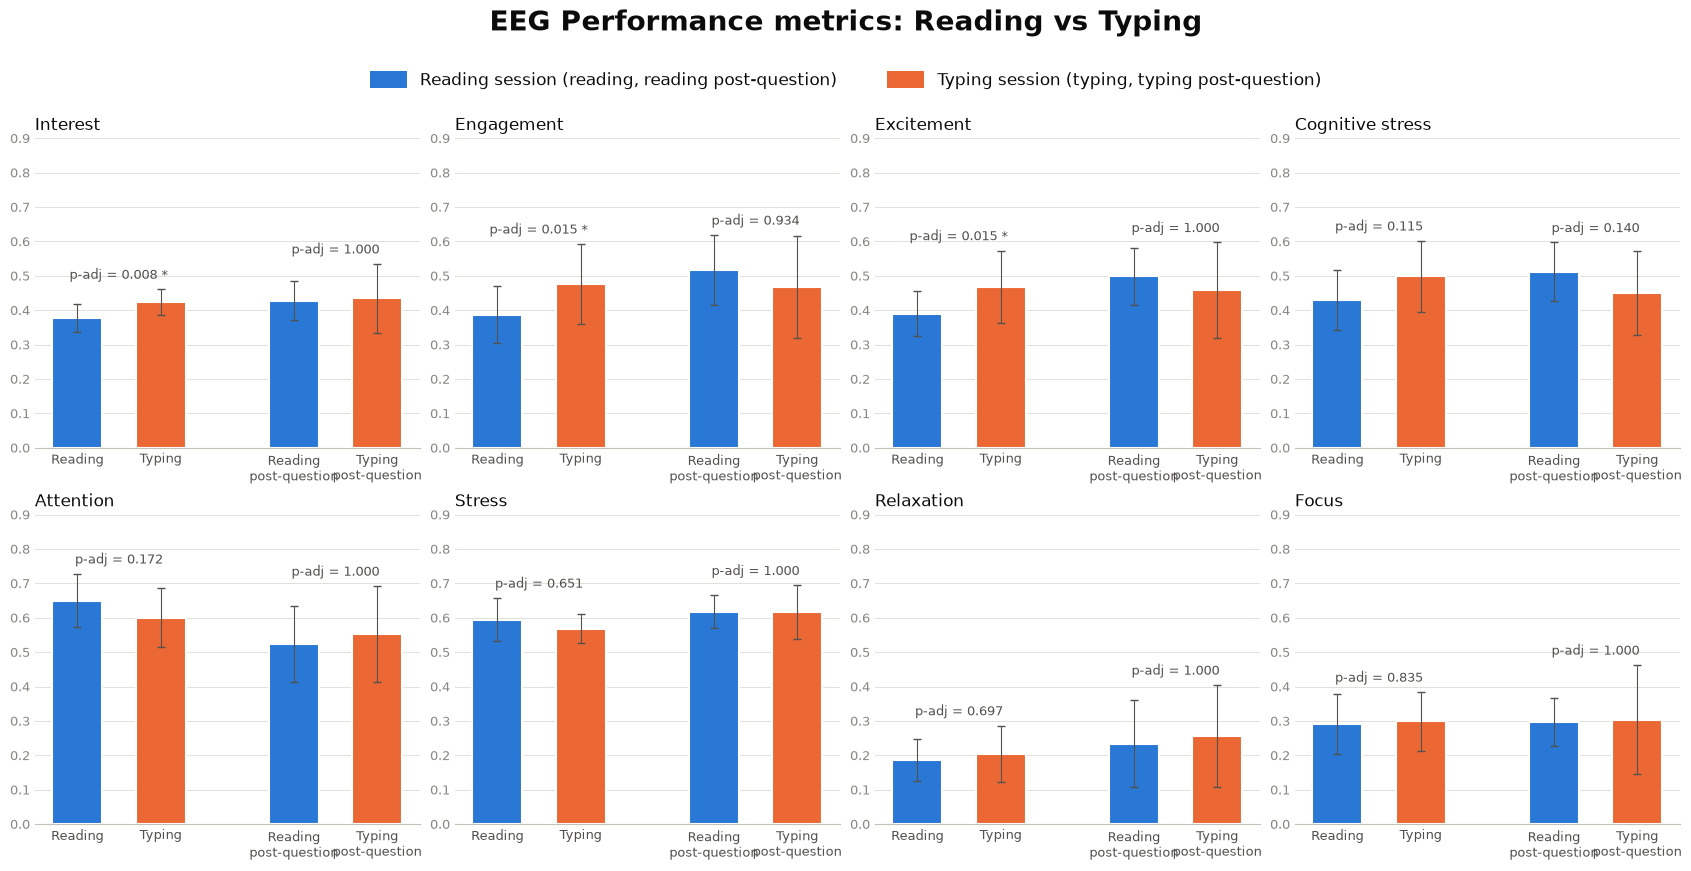

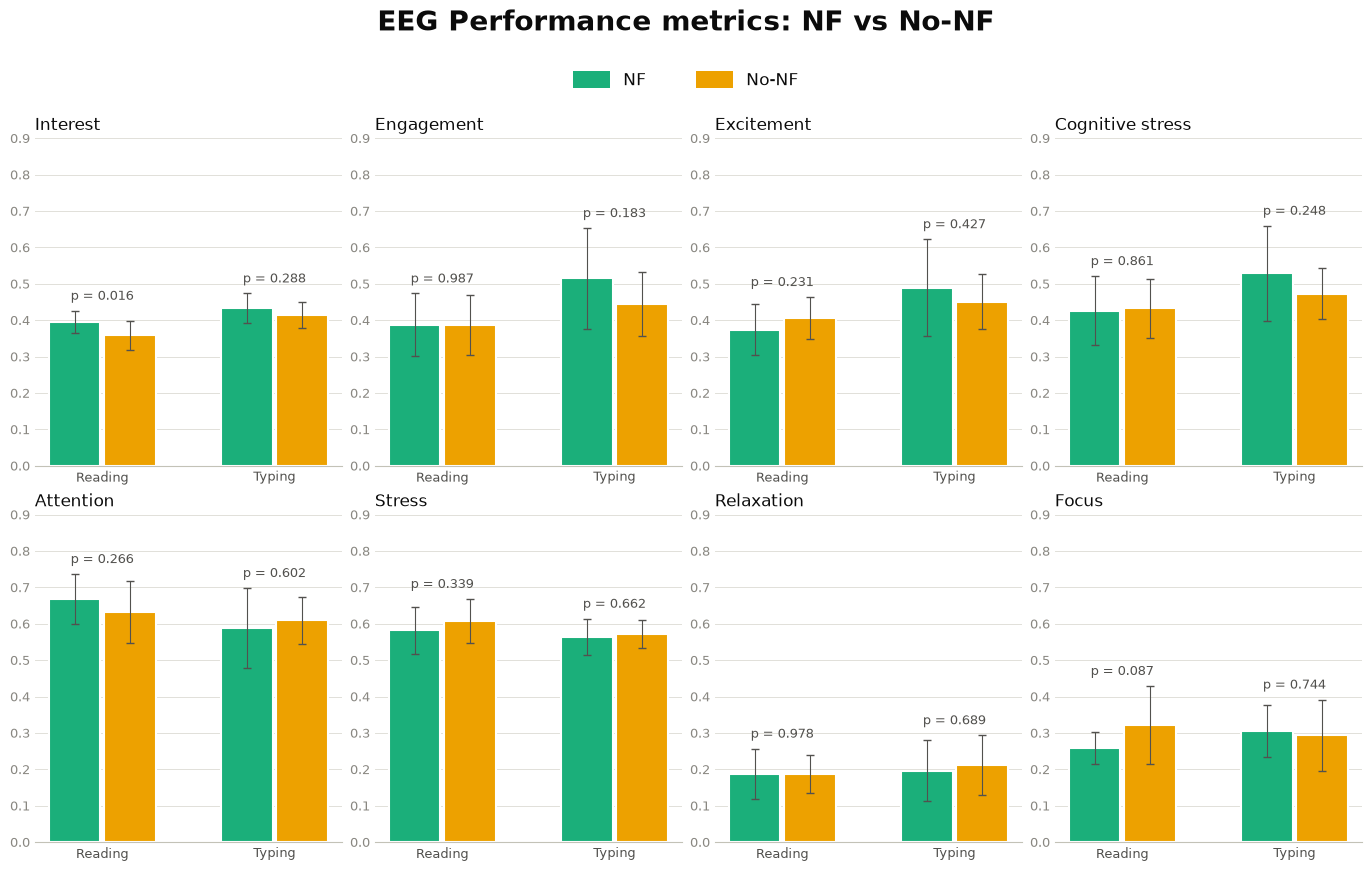

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SHOW = ["Attention", "Engagement", "Excitement", "Focus",   # the metrics to plot; delete any you do not want
        "Interest", "Relaxation", "Stress", "Cognitivestress"]
SHOW = [m for m in tests.index if m in SHOW]                 # same order as the tests table: significant first

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
READING, TYPING, NF, NO_NF = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GROUPS = [["Reading", "Typing"],                             # bars side by side within a group,
          ["Reading post-question", "Typing post-question"]]  # a gap between the groups
READING_SESSION = ["Reading", "Reading post-question"]       # blue; the typing-session phases are orange
ERR = dict(ecolor=INK_2, elinewidth=0.8, capsize=3)
BAR = dict(edgecolor=SURFACE, linewidth=1.5)                 # a thin white gap between touching bars

from PIL import Image

def save_png(fig, file):                                   # white background without a transparency layer
    fig.savefig(file, dpi=200, facecolor=SURFACE, bbox_inches="tight")
    Image.open(file).convert("RGB").save(file)

def panels(ncols, width, title, legend):
    ncols = min(ncols, len(SHOW))
    nrows = -(-len(SHOW) // ncols)
    fig = plt.figure(figsize=(width * ncols, 3.8 * nrows + 1.0), facecolor=SURFACE, layout="constrained")
    head, body = fig.subfigures(2, 1, height_ratios=[1.0, 3.8 * nrows], facecolor=SURFACE)
    head.suptitle(title, color=INK, fontsize=20, fontweight="bold")              # centred, large
    head.legend(handles=[Patch(facecolor=c, label=l) for l, c in legend], loc="lower center",
                ncol=len(legend), frameon=False, fontsize=12, labelcolor=INK,    # colour key under the title
                handlelength=2.2, handleheight=1.2, columnspacing=3)
    axes = body.subplots(nrows, ncols, squeeze=False)
    for ax in axes.flat[len(SHOW):]:
        ax.set_visible(False)
    return fig, axes.flat[:len(SHOW)]

def style(ax, metric, positions, labels, ymax):
    ax.set_facecolor(SURFACE)
    ax.set_title(metric, loc="left", color=INK, fontsize=12)
    ax.set_xticks(positions, labels, fontsize=9, color=INK_2)
    ax.set_ylim(0, ymax)
    ax.tick_params(length=0, labelsize=9)
    ax.tick_params(axis="y", labelcolor=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.7)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)

# 1. reading and typing side by side, then the two post-questions side by side, with p-adj (Holm) above each pair
shown = [ph for group in GROUPS for ph in group]
pos = [start + i for k, group in enumerate(GROUPS)
       for start in [sum(len(g) + 0.6 for g in GROUPS[:k])] for i in range(len(group))]
mean, sd = summary.xs("mean", axis=1, level=1), summary.xs("SD", axis=1, level=1)
ymax = np.ceil(10 * ((mean + sd).loc[shown, SHOW].max().max() + 0.08)) / 10   # room for the p-adj above the bars
fig, axes = panels(4, 4.2, f"{TITLE}: Reading vs Typing",
                   [("Reading session (reading, reading post-question)", READING),
                    ("Typing session (typing, typing post-question)", TYPING)])
for ax, m in zip(axes, SHOW):
    ax.bar(pos, mean.loc[shown, m], 0.6, yerr=sd.loc[shown, m],
           color=[READING if ph in READING_SESSION else TYPING for ph in shown], error_kw=ERR, **BAR)
    for group in GROUPS:
        name = next((k for k, pair in PAIRS.items() if set(pair) == set(group)), None)   # the paired test of this group
        if name:
            p = tests.loc[m, (name, "p-adj (Holm)")]
            ax.text(np.mean([pos[shown.index(ph)] for ph in group]),
                    max(mean.loc[ph, m] + sd.loc[ph, m] for ph in group) + 0.03,
                    ("p-adj < 0.001" if p < 0.001 else f"p-adj = {p:.3f}") + (" *" if p < 0.05 else ""),
                    ha="center", color=INK_2, fontsize=9)
    style(ax, LABELS[m], pos, [ph.replace(" ", "\n", 1) for ph in shown], ymax)
save_png(fig, FIGS / f"pm_group_bars_{EXPORT}.png")
plt.show()
n = summary[("n", "")]
FIGURES[str(FIGS / f"pm_group_bars_{EXPORT}.png")] = (f"{TITLE}: Reading vs Typing",
    rf"Mean across participants on Emotiv's 0--1 scale; error bars show the SD between participants "
    rf"(reading $n = {n['Reading']}$, typing $n = {n['Typing']}$, post-questions $n = {n['Reading post-question']}$). "
    r"Above each pair: $p$ of the paired $t$-test, Holm-adjusted over the eight metrics; * $p_{\mathrm{Holm}} < 0.05$.")

# 2. NF check: NF against No-NF for reading and typing, with the Welch t-test p above each pair
sessions = ["Reading", "Typing"]
top = {(ph, m): max(nf_check.loc[(ph, m), g] + nf_check.loc[(ph, m), g + " SD"] for g in ["NF", "No-NF"])
       for ph in sessions for m in SHOW}
fig, axes = panels(4, 3.4, f"{TITLE}: NF vs No-NF", [("NF", NF), ("No-NF", NO_NF)])
for ax, m in zip(axes, SHOW):
    for dx, g, color in [(-0.16, "NF", NF), (0.16, "No-NF", NO_NF)]:
        ax.bar(np.arange(2) + dx, [nf_check.loc[(ph, m), g] for ph in sessions], 0.3,
               yerr=[nf_check.loc[(ph, m), g + " SD"] for ph in sessions], color=color, error_kw=ERR, **BAR)
    for i, ph in enumerate(sessions):
        ax.text(i, top[(ph, m)] + 0.03, f"p = {nf_check.loc[(ph, m), 'p']:.3f}", ha="center", color=INK_2, fontsize=9)
    style(ax, LABELS[m], range(2), sessions, np.ceil(10 * max(top.values()) + 1) / 10)
save_png(fig, FIGS / f"pm_nf_check_{EXPORT}.png")
plt.show()
k = nf_check.loc[sessions[0]].iloc[0], nf_check.loc[sessions[1]].iloc[0]
FIGURES[str(FIGS / f"pm_nf_check_{EXPORT}.png")] = (f"{TITLE}: NF vs No-NF",
    rf"Mean $\pm$ SD. Above each pair: unadjusted $p$ of the Welch $t$-test of NF against No-NF "
    rf"(reading: NF $n = {int(k[0]['n NF'])}$, No-NF $n = {int(k[0]['n No-NF'])}$; "
    rf"typing: NF $n = {int(k[1]['n NF'])}$, No-NF $n = {int(k[1]['n No-NF'])}$).")